# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Anggela Merici Moruk
- NIM   : 241011401654
- Kelas : Reg B 

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [ ]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE =  54


In [3]:
# Salin fungsi train_test_split dari materi di sini
def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)

    indices = np.arange(len(X))
    np.random.shuffle(indices)

    test_set_size = int(len(X) * test_size)
    test_indices = indices[:test_set_size]
    train_indices = indices[test_set_size:]

    if isinstance(X, pd.DataFrame) or isinstance(X, pd.Series):
        X_train, X_test = X.iloc[train_indices], X.iloc[test_indices]
    else:
        X_train, X_test = X[train_indices], X[test_indices]

    if isinstance(y, pd.DataFrame) or isinstance(y, pd.Series):
        y_train, y_test = y.iloc[train_indices], y.iloc[test_indices]
    else:
        y_train, y_test = y[train_indices], y[test_indices]

    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

Jumlah baris data: 40


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


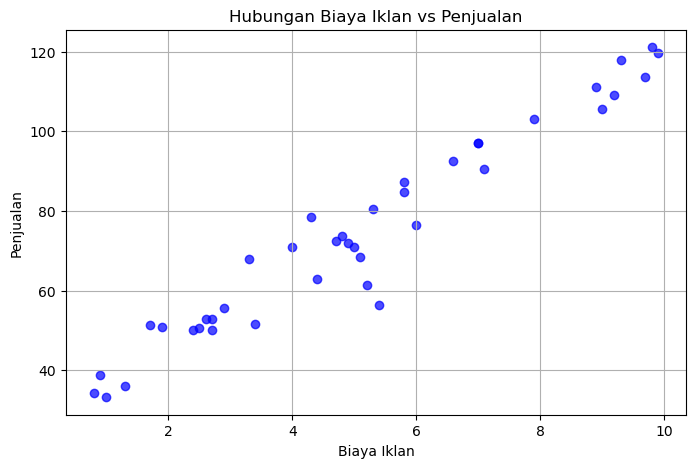

In [4]:
# Jawaban A1
# 1. Baca Ads_Data.csv dan tampilkan 5 data pertama serta jumlah barisnya
df_ads = pd.read_csv('Ads_Data.csv')
print(f"Jumlah baris data: {len(df_ads)}")
display(df_ads.head())

# 2. Pisahkan X (BiayaIklan) dan y (Penjualan), pastikan X berbentuk 2 dimensi (n, 1)
X = df_ads[['BiayaIklan']]
y = df_ads['Penjualan']

# 3. Buat scatter plot BiayaIklan vs Penjualan
plt.figure(figsize=(8, 5))
plt.scatter(df_ads['BiayaIklan'], df_ads['Penjualan'], color='blue', alpha=0.7)
plt.title('Hubungan Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan')
plt.ylabel('Penjualan')
plt.grid(True)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [8]:
# Jawaban A2
# Split dataset menjadi Data Training (80%) dan Testing (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

# Tampilkan shape dari masing-masing variabel
print("Shape X_train:", X_train.shape)
print("Shape X_test :", X_test.shape)
print("Shape y_train:", y_train.shape)
print("Shape y_test :", y_test.shape)

Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [9]:
# Jawaban A3
# 1. Tambahkan kolom bias (intercept) bernilai 1 pada X_train
X_b = np.c_[np.ones((len(X_train), 1)), X_train]

# 2. Hitung theta menggunakan Normal Equation
theta_best = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y_train)

# Tampilkan intercept (b) dan koefisien (m)
b = theta_best[0]
m = theta_best[1]

print(f"Intercept (b)  : {b:.4f}")
print(f"Koefisien (m)  : {m:.4f}")
print(f"Persamaan Garis: y_hat = {b:.4f} + {m:.4f} * X")

Intercept (b)  : 27.8884
Koefisien (m)  : 9.3474
Persamaan Garis: y_hat = 27.8884 + 9.3474 * X


**Jawaban A3 (interpretasi):** Setiap kenaikan biaya iklan sebesar 1 juta Rp, penjualan diperkirakan akan meningkat sebesar 9.3474 unit (atau sekitar 9.35 unit).

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [10]:
# Jawaban A4
# 1. Definisikan fungsi evaluasi berbasis NumPy sesuai rumus
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

# Hitung prediksi untuk Data Training dan Data Testing
X_test_b = np.c_[np.ones((len(X_test), 1)), X_test]

y_pred_train = X_b.dot(theta_best)
y_pred_test = X_test_b.dot(theta_best)

# 2. Tampilkan hasil evaluasi dalam satu DataFrame
eval_results = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2 Score'],
    'Data Training': [
        mae(y_train, y_pred_train),
        mse(y_train, y_pred_train),
        rmse(y_train, y_pred_train),
        r2_score(y_train, y_pred_train)
    ],
    'Data Testing': [
        mae(y_test, y_pred_test),
        mse(y_test, y_pred_test),
        rmse(y_test, y_pred_test),
        r2_score(y_test, y_pred_test)
    ]
})

display(eval_results)

,Metric,Data Training,Data Testing
0,MAE,3.880198,6.446382
1,MSE,26.280105,80.749225
2,RMSE,5.126413,8.986057
3,R2 Score,0.957327,0.824097


**Jawaban A4 (analisis):**
1. Nilai RMSE: Rata-rata kesalahan prediksi penjualan pada data latih sebesar 5.13 dan pada data uji sebesar 8.99. Selisih error ini masih tergolong wajar.

2. Nilai $R^2$ Score: Model mampu menjelaskan variasi penjualan sebesar 95.7% pada data latih dan 82.4% pada data uji.

Kesimpulan Performa: Model linear regression ini sudah tergolong sangat baik karena nilai $R^2$ pada data uji di atas 0.8 (80%) dan tidak menunjukkan indikasi over-fitting yang parah.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

LR 0.001 -> Intercept: 27.8879, Koefisien: 9.3469
LR 0.02 -> Intercept: 27.8884, Koefisien: 9.3474
LR 0.1 -> Intercept: 27.8884, Koefisien: 9.3474


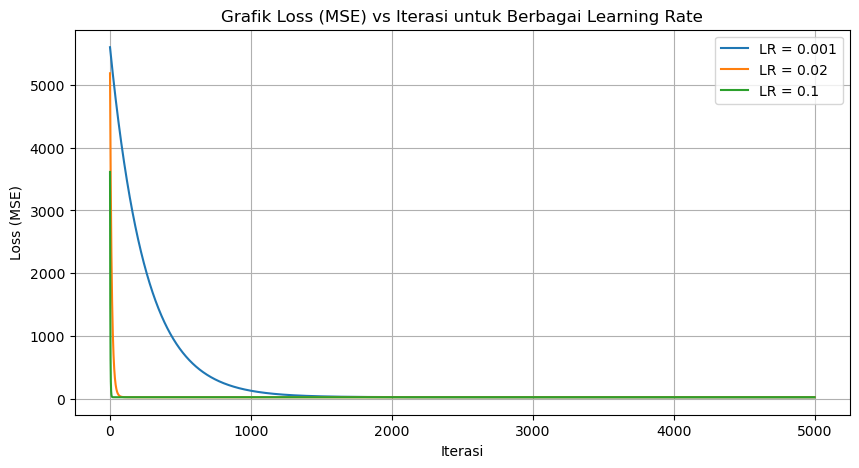

In [12]:
# Jawaban A5
# Standarisasi fitur agar Gradient Descent stabil
X_mean, X_std = X_train.mean().values[0], X_train.std().values[0]
X_train_scaled = (X_train - X_mean) / X_std

X_b_scaled = np.c_[np.ones((len(X_train_scaled), 1)), X_train_scaled]
y_vec = y_train.values.reshape(-1, 1)

lrs = [0.001, 0.02, 0.1]
n_iterations = 5000

plt.figure(figsize=(10, 5))

for lr in lrs:
    theta = np.zeros((2, 1))
    cost_history = []
    
    for iteration in range(n_iterations):
        gradients = (2/len(X_b_scaled)) * X_b_scaled.T.dot(X_b_scaled.dot(theta) - y_vec)
        theta = theta - lr * gradients
        cost = np.mean((X_b_scaled.dot(theta) - y_vec)**2)
        cost_history.append(cost)
    
    # Konversi theta kembali ke skala asli
    m_orig = theta[1][0] / X_std
    b_orig = theta[0][0] - (theta[1][0] * X_mean / X_std)
    
    print(f"LR {lr} -> Intercept: {b_orig:.4f}, Koefisien: {m_orig:.4f}")
    plt.plot(cost_history, label=f'LR = {lr}')

plt.xlabel('Iterasi')
plt.ylabel('Loss (MSE)')
plt.title('Grafik Loss (MSE) vs Iterasi untuk Berbagai Learning Rate')
plt.legend()
plt.grid(True)
plt.show()

**Jawaban A5 (analisis):**
1. **Perbandingan Hasil**:
   - **LR = 0.02** dan **LR = 0.1** menghasilkan nilai **Intercept (27.8884)** dan **Koefisien (9.3474)** yang persis sama dengan hasil *Normal Equation* pada Soal A3.
   - **LR = 0.001** menghasilkan nilai yang mendekati, namun sedikit lebih lambat konvergen dibandingkan dua learning rate lainnya.

2. **Analisis Konvergensi & Karakteristik Learning Rate**:
   - **LR = 0.001 (Terlalu Lambat)**: Kurva *loss* membutuhkan iterasi yang lebih banyak untuk mencapai titik minimum.
   - **LR = 0.02 (Optimal/Pas)**: Model konvergen secara efisien dan stabil menuju nilai optimum tanpa bergejolak.
   - **LR = 0.1 (Cepat Konvergen)**: Pada data yang telah ter-standarisasi (*feature scaling*), LR 0.1 mampu konvergen sangat cepat menuju titik minimum. Jika data tidak di-standarisasi, LR 0.1 berisiko mengalami *divergen/overshooting*.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

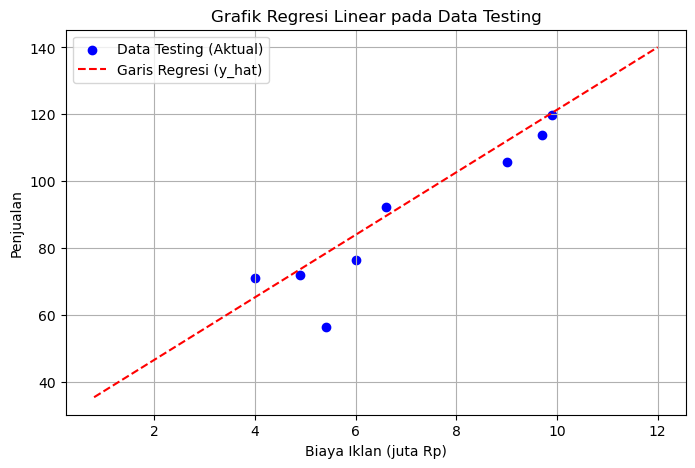

Prediksi penjualan untuk Biaya Iklan  4.5 juta Rp: 69.95
Prediksi penjualan untuk Biaya Iklan  7.0 juta Rp: 93.32
Prediksi penjualan untuk Biaya Iklan 12.0 juta Rp: 140.06


In [13]:
# Jawaban A6
# 1. Buat grafik scatter data testing beserta garis regresi (hasil Soal A3)
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color='blue', label='Data Testing (Aktual)')

# Garis regresi
x_line = np.linspace(X['BiayaIklan'].min(), 12, 100)
y_line = b + m * x_line
plt.plot(x_line, y_line, color='red', linestyle='--', label='Garis Regresi (y_hat)')

plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan')
plt.title('Grafik Regresi Linear pada Data Testing')
plt.legend()
plt.grid(True)
plt.show()

# 2. Prediksi penjualan untuk biaya iklan 4.5 juta, 7 juta, dan 12 juta
biaya_baru = np.array([4.5, 7.0, 12.0])
prediksi = b + m * biaya_baru

for ikln, pred in zip(biaya_baru, prediksi):
    print(f"Prediksi penjualan untuk Biaya Iklan {ikln:>4.1f} juta Rp: {pred:.2f}")

**Jawaban A6 (analisis):**
1. Hasil Prediksi:
   - Biaya Iklan 4.5 juta Rp -> Prediksi Penjualan: 69.95
   - Biaya Iklan 7.0 juta Rp -> Prediksi Penjualan: 93.32
   - Biaya Iklan 12.0 juta Rp -> Prediksi Penjualan: 140.06

2. Kepercayaan Hasil Prediksi untuk 12 Juta Rp (Ekstrapolasi):
   - Tingkat Kepercayaan Rendah / Perlu Berhati-hati: Nilai 12 juta berada di luar rentang data historis (ekstrapolasi), di mana data asli hanya berada pada kisaran 1–10 juta.
   - Alasan: Model mengasumsikan bahwa hubungan linear akan terus berlanjut tanpa batas. Dalam kondisi riil, peningkatan biaya iklan yang sangat besar sering mengalami kejenuhan pasar (diminishing returns), sehingga hasilnya belum tentu selalu linear secara terus-menerus.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 Data Pertama Email_Data.csv:


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1



Jumlah email Spam (1) dan Bukan Spam (0):
Bukan Spam (0): 35
Spam (1)      : 25


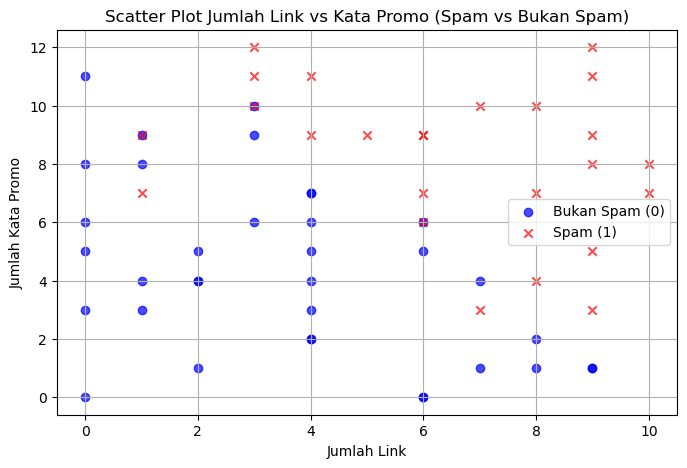

In [14]:
# Jawaban B1
# 1. Baca Email_Data.csv dan tampilkan 5 data pertama
df_email = pd.read_csv('Email_Data.csv')
print("5 Data Pertama Email_Data.csv:")
display(df_email.head())

# Hitung jumlah email Spam dan Bukan Spam
spam_counts = df_email['Spam'].value_counts()
print("\nJumlah email Spam (1) dan Bukan Spam (0):")
print(f"Bukan Spam (0): {spam_counts.get(0, 0)}")
print(f"Spam (1)      : {spam_counts.get(1, 0)}")

# 2. Pisahkan X (JumlahLink, KataPromo) dan y (Spam)
X_email = df_email[['JumlahLink', 'KataPromo']]
y_email = df_email['Spam']

# 3. Buat scatter plot JumlahLink vs KataPromo dengan warna berbeda
plt.figure(figsize=(8, 5))
plt.scatter(
    df_email[df_email['Spam'] == 0]['JumlahLink'],
    df_email[df_email['Spam'] == 0]['KataPromo'],
    color='blue', label='Bukan Spam (0)', alpha=0.7
)
plt.scatter(
    df_email[df_email['Spam'] == 1]['JumlahLink'],
    df_email[df_email['Spam'] == 1]['KataPromo'],
    color='red', label='Spam (1)', marker='x', alpha=0.7
)

plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.title('Scatter Plot Jumlah Link vs Kata Promo (Spam vs Bukan Spam)')
plt.legend()
plt.grid(True)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Intercept (b)      : -15.1396
Koefisien m1 (Link): 1.3306
Koefisien m2 (Promo): 1.2444

Persamaan Model Logistic Regression:
P(Spam) = sigma(-15.1396 + 1.3306 * JumlahLink + 1.2444 * KataPromo)


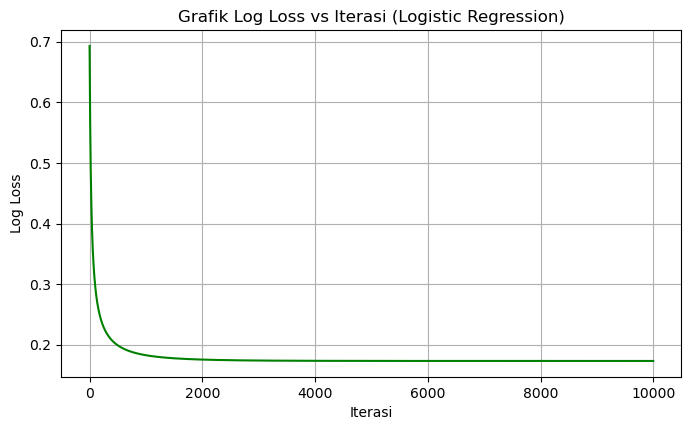

In [15]:
# Jawaban B2
# 1. Split Data (test_size=0.25, random_state=RANDOM_STATE)
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

# Standarisasi Fitur untuk Logistic Regression Gradient Descent
X_mean_e = X_train_e.mean()
X_std_e = X_train_e.std()

X_train_scaled_e = (X_train_e - X_mean_e) / X_std_e
X_test_scaled_e = (X_test_e - X_mean_e) / X_std_e

# Tambahkan kolom bias (intercept)
X_b_train_e = np.c_[np.ones((len(X_train_scaled_e), 1)), X_train_scaled_e]
y_vec_e = y_train_e.values.reshape(-1, 1)

# Sigmoid Function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# 2. Training Logistic Regression dengan Gradient Descent
learning_rate = 0.1
n_iterations = 10000

theta_e = np.zeros((3, 1))
loss_history = []
m_samples = len(X_b_train_e)

for iteration in range(n_iterations):
    z = X_b_train_e.dot(theta_e)
    h = sigmoid(z)
    
    # Clip h agar terhindar dari log(0)
    h = np.clip(h, 1e-15, 1 - 1e-15)
    
    # Hitung Log Loss (Binary Cross-Entropy)
    log_loss = - (1 / m_samples) * np.sum(y_vec_e * np.log(h) + (1 - y_vec_e) * np.log(1 - h))
    loss_history.append(log_loss)
    
    # Gradient Update
    gradients = (1 / m_samples) * X_b_train_e.T.dot(h - y_vec_e)
    theta_e -= learning_rate * gradients

# Konversi theta kembali ke skala fitur asli
m1_orig = theta_e[1][0] / X_std_e['JumlahLink']
m2_orig = theta_e[2][0] / X_std_e['KataPromo']
b_orig = theta_e[0][0] - (theta_e[1][0] * X_mean_e['JumlahLink'] / X_std_e['JumlahLink']) - (theta_e[2][0] * X_mean_e['KataPromo'] / X_std_e['KataPromo'])

# 3. Tampilkan Intercept (b) dan Koefisien (m1, m2)
print(f"Intercept (b)      : {b_orig:.4f}")
print(f"Koefisien m1 (Link): {m1_orig:.4f}")
print(f"Koefisien m2 (Promo): {m2_orig:.4f}")
print(f"\nPersamaan Model Logistic Regression:")
print(f"P(Spam) = sigma({b_orig:.4f} + {m1_orig:.4f} * JumlahLink + {m2_orig:.4f} * KataPromo)")

# 4. Grafik Log Loss vs Iterasi
plt.figure(figsize=(8, 4.5))
plt.plot(loss_history, color='green')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.title('Grafik Log Loss vs Iterasi (Logistic Regression)')
plt.grid(True)
plt.show()

**Jawaban B2 (analisis):**
1. **Perkembangan Loss**:
   - Grafik menunjukkan bahwa nilai **Log Loss** mengalami penurunan yang signifikan pada 1.000 iterasi pertama, lalu terus melandai secara mulus hingga mendatar secara stabil menuju titik konvergen (sekitar ~0.17).

2. **Kestabilan & Konvergensi Model**:
   - Dengan pengaturan `learning_rate = 0.1` dan `n_iterations = 10000`, model terlatih secara optimal tanpa mengalami osilasi atau *overflow*.
   - Nilai loss yang telah mendatar dan stabil menandakan bahwa model telah berhasil menemukan bobot intercept ($b = -15.1396$) serta koefisien ($m_1 = 1.3306, m_2 = 1.2444$) yang presisi untuk membedakan email Spam dan Bukan Spam.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [16]:
# Jawaban B3
# Prediksi probabilitas dan kelas pada data testing
z_test = X_b_test_e.dot(theta_e) if 'X_b_test_e' in locals() else np.c_[np.ones((len(X_test_scaled_e), 1)), X_test_scaled_e].dot(theta_e)
y_pred_proba = sigmoid(z_test)
y_pred = (y_pred_proba >= 0.5).astype(int).flatten()

# Implementasi Fungsi Evaluasi Manual
def manual_confusion_matrix(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    return np.array([[tn, fp], [fn, tp]]), tp, fp, fn, tn

def manual_accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)

def manual_precision(tp, fp):
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def manual_recall(tp, fn):
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def manual_f1_score(precision, recall):
    return 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0

# Hitung Metrik
cm, tp, fp, fn, tn = manual_confusion_matrix(y_train_e.values if False else y_test_e.values, y_pred)
acc = manual_accuracy(y_test_e.values, y_pred)
prec = manual_precision(tp, fp)
rec = manual_recall(tp, fn)
f1 = manual_f1_score(prec, rec)

print("--- Evaluasi Model Logistic Regression (Data Testing) ---")
print(f"Confusion Matrix:\n{cm}")
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}")

--- Evaluasi Model Logistic Regression (Data Testing) ---
Confusion Matrix:
[[8 1]
 [2 4]]
Accuracy  : 0.8000
Precision : 0.8000
Recall    : 0.6667
F1-Score  : 0.7273


**Jawaban B3 (analisis):**
1. **Arti False Positive (FP) dan False Negative (FN)**:
   - **False Positive (FP)**: Email **Bukan Spam (normal)** yang salah terklasifikasi oleh model sebagai **Spam**.
   - **False Negative (FN)**: Email **Spam** yang gagal terdeteksi dan malah dianggap sebagai email **Bukan Spam (normal)**.

2. **Analisis Kesalahan yang Lebih Merugikan**:
   - Kesalahan **False Positive (FP) jauh lebih merugikan pengguna email**.
   - **Alasan**: Jika terjadi FP, email penting (seperti tawaran pekerjaan, pesan bisnis, verifikasi akun, atau tugas kuliah) akan langsung terlempar ke folder spam dan berisiko tinggi terlewat oleh pengguna. Sebaliknya, jika terjadi FN, dampak terburuknya pengguna hanya sekadar melihat email promosi/spam masuk ke inbox utama dan bisa menghapusnya secara manual.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Persamaan Decision Boundary:
KataPromo = (15.1396 - 1.3306 * JumlahLink) / 1.2444


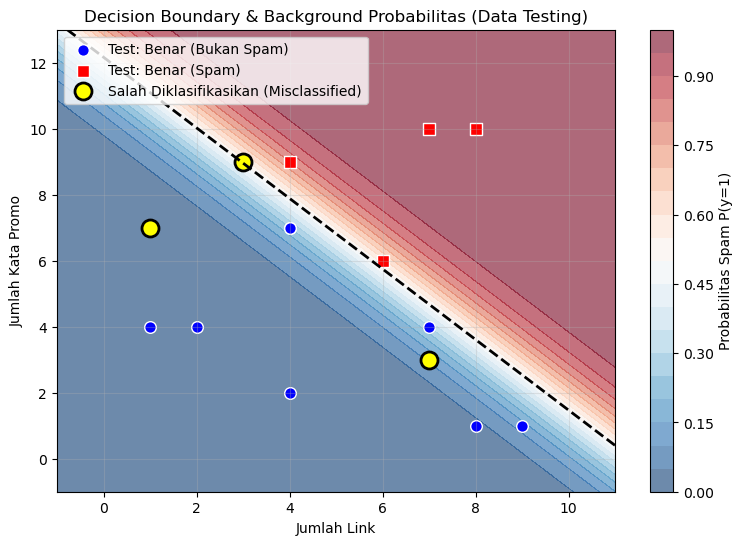


Jumlah data testing yang salah diklasifikasikan: 3 dari 15 data


In [18]:
# Jawaban B4
# 1. Hitung persamaan decision boundary (saat z = 0)
val_b = -b_orig
print("Persamaan Decision Boundary:")
print(f"KataPromo = ({val_b:.4f} - {m1_orig:.4f} * JumlahLink) / {m2_orig:.4f}")

# 2. Buat meshgrid untuk background probabilitas (contourf)
x_min, x_max = X_email['JumlahLink'].min() - 1, X_email['JumlahLink'].max() + 1
y_min, y_max = X_email['KataPromo'].min() - 1, X_email['KataPromo'].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))

# Standardisasi poin-poin meshgrid untuk prediksi probabilitas
grid_scaled = np.c_[(xx.ravel() - X_mean_e['JumlahLink']) / X_std_e['JumlahLink'],
                    (yy.ravel() - X_mean_e['KataPromo']) / X_std_e['KataPromo']]
grid_b = np.c_[np.ones((len(grid_scaled), 1)), grid_scaled]
Z = sigmoid(grid_b.dot(theta_e)).reshape(xx.shape)

plt.figure(figsize=(9, 6))

# Plot background probabilitas
contour = plt.contourf(xx, yy, Z, levels=20, cmap='RdBu_r', alpha=0.6)
plt.colorbar(contour, label='Probabilitas Spam P(y=1)')

# Plot garis Decision Boundary (P = 0.5)
plt.contour(xx, yy, Z, levels=[0.5], colors='black', linewidths=2, linestyles='--')

# Filter data testing yang benar vs salah diklasifikasikan
correct_mask = (y_test_e.values == y_pred)
incorrect_mask = ~correct_mask

# Plot data testing yang benar
plt.scatter(
    X_test_e[correct_mask & (y_test_e == 0)]['JumlahLink'],
    X_test_e[correct_mask & (y_test_e == 0)]['KataPromo'],
    color='blue', edgecolors='white', s=70, label='Test: Benar (Bukan Spam)'
)
plt.scatter(
    X_test_e[correct_mask & (y_test_e == 1)]['JumlahLink'],
    X_test_e[correct_mask & (y_test_e == 1)]['KataPromo'],
    color='red', edgecolors='white', marker='s', s=70, label='Test: Benar (Spam)'
)

# 3. Beri tanda lingkaran kuning besar pada data testing yang salah diklasifikasikan
plt.scatter(
    X_test_e[incorrect_mask]['JumlahLink'],
    X_test_e[incorrect_mask]['KataPromo'],
    color='yellow', edgecolors='black', linewidths=2, marker='o', s=150,
    label='Salah Diklasifikasikan (Misclassified)'
)

plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.title('Decision Boundary & Background Probabilitas (Data Testing)')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.show()

# Print detail data yang salah diklasifikasikan
print(f"\nJumlah data testing yang salah diklasifikasikan: {np.sum(incorrect_mask)} dari {len(y_test_e)} data")

**Jawaban B4 (analisis):**
1. **Persamaan Decision Boundary**:
   - Persamaan garis pemisah ($z = 0$) dirumuskan sebagai:  
     $$\text{KataPromo} = \frac{15.1396 - 1.3306 \cdot \text{JumlahLink}}{1.2444}$$
   - Garis ini memisahkan wilayah dengan probabilitas $P(\text{Spam}) \ge 0.5$ (area merah) dan $P(\text{Spam}) < 0.5$ (area biru).

2. **Analisis Data yang Salah Diklasifikasikan**:
   - Terdapat **3 sampel data testing** yang salah diklasifikasikan (*misclassified*), ditandai dengan lingkaran kuning bergaris tepi hitam pada grafik.
   - Poin-poin kesalahan ini berada dekat dengan area perbatasan (*decision boundary*), di mana kombinasi jumlah link dan kata promosi berada pada wilayah ambigu antara email Spam dan Bukan Spam.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [19]:
# Jawaban B5
thresholds = [0.3, 0.5, 0.7]
results = []

for th in thresholds:
    # Prediksi dengan threshold tertentu
    y_pred_th = (y_pred_proba >= th).astype(int).flatten()
    
    # Hitung Confusion Matrix, Precision, dan Recall
    cm_th, tp_th, fp_th, fn_th, tn_th = manual_confusion_matrix(y_test_e.values, y_pred_th)
    prec_th = manual_precision(tp_th, fp_th)
    rec_th = manual_recall(tp_th, fn_th)
    
    results.append({
        'Threshold': th,
        'TP': tp_th,
        'FP': fp_th,
        'FN': fn_th,
        'TN': tn_th,
        'Precision': f"{prec_th:.4f}",
        'Recall': f"{rec_th:.4f}"
    })

# Tampilkan hasil eksperimen dalam bentuk tabel DataFrame
df_results = pd.DataFrame(results)
print("--- Hasil Eksperimen Threshold (Data Testing) ---")
display(df_results)

--- Hasil Eksperimen Threshold (Data Testing) ---


,Threshold,TP,FP,FN,TN,Precision,Recall
0,0.3,4,1,2,8,0.8000,0.6667
1,0.5,4,1,2,8,0.8000,0.6667
2,0.7,3,0,3,9,1.0000,0.5000


**Jawaban B5 (analisis):**
1. **Pengaruh Perubahan Threshold**:
   - **Menaikkan Threshold (0.7)**: Membuat model lebih selektif dalam memprediksi Spam. Hasil eksperimen menunjukkan nilai **FP turun menjadi 0** sehingga **Precision naik menjadi 1.0000** (100%), walaupun Recall turun menjadi 0.5000.
   - **Menurunkan Threshold (0.3)**: Pada dataset testing ini, menurunkan threshold ke 0.3 memberikan hasil yang sama dengan 0.5 (Precision 0.8000 dan Recall 0.6667).

2. **Pemilihan Threshold Terbaik untuk Filter Spam**:
   - **Threshold yang Dipilih: 0.7**.
   - **Alasan**: Sesuai analisis pada Soal B3, kesalahan *False Positive* (FP) sangat merugikan karena menyebabkan email penting masuk ke folder spam. Dengan threshold 0.7, model mencapai **Precision 1.0000 (FP = 0)**, sehingga dijamin tidak ada email normal yang salah terbuang ke folder spam.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [20]:
# Jawaban B6
# Data email baru sesuai tabel
new_emails = pd.DataFrame({
    'Email': ['E1', 'E2', 'E3', 'E4'],
    'JumlahLink': [1, 5, 9, 2],
    'KataPromo': [2, 6, 10, 11]
})

# Threshold pilihan dari Soal B5
best_threshold = 0.7

# Standardisasi fitur data baru menggunakan mean dan std dari data training
X_new = new_emails[['JumlahLink', 'KataPromo']]
X_new_scaled = (X_new - X_mean_e) / X_std_e

# Tambahkan kolom bias (intercept)
X_b_new = np.c_[np.ones((len(X_new_scaled), 1)), X_new_scaled]

# Hitung probabilitas spam
prob_new = sigmoid(X_b_new.dot(theta_e)).flatten()

# Prediksi kelas berdasarkan threshold 0.7
pred_new = (prob_new >= best_threshold).astype(int)

# Masukkan hasil ke DataFrame
new_emails['Probabilitas Spam'] = [f"{p:.4f}" for p in prob_new]
new_emails['Prediksi (Threshold 0.7)'] = ['Spam (1)' if p == 1 else 'Bukan Spam (0)' for p in pred_new]

print(f"--- Hasil Prediksi Email Baru (Threshold = {best_threshold}) ---")
display(new_emails)

--- Hasil Prediksi Email Baru (Threshold = 0.7) ---


,Email,JumlahLink,KataPromo,Probabilitas Spam,Prediksi (Threshold 0.7)
0,E1,1,2,0.0000,Bukan Spam (0)
1,E2,5,6,0.2650,Bukan Spam (0)
2,E3,9,10,0.9999,Spam (1)
3,E4,2,11,0.7703,Spam (1)


### Jawaban B6 (analisis):

1. **Hasil Prediksi Email Baru**:
   - Prediksi kelas email baru menggunakan model Logistic Regression dengan **threshold 0.7** (pilihan optimal dari Soal B5).
   - **E1**: Probabilitas = 0.0000 < 0.7 $\rightarrow$ **Bukan Spam (0)**
   - **E2**: Probabilitas = 0.2650 < 0.7 $\rightarrow$ **Bukan Spam (0)**
   - **E3**: Probabilitas = 0.9999 $\ge$ 0.7 $\rightarrow$ **Spam (1)**
   - **E4**: Probabilitas = 0.7703 $\ge$ 0.7 $\rightarrow$ **Spam (1)**

2. **Analisis Singkat**:
   - Email **E1** dan **E2** memiliki kombinasi jumlah link serta kata promosi yang relatif rendah sehingga dikategorikan sebagai email normal/bukan spam.
   - Email **E3** dan **E4** memiliki jumlah kata promosi yang sangat tinggi (10 dan 11), sehingga probabilitas spam-nya melampaui threshold 0.7 dan diklasifikasikan sebagai **Spam**.

---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression digunakan untuk memprediksi kategori, misalnya spam atau bukan spam. Disebut regression karena menggunakan perhitungan yang mirip dengan regresi linier. Fungsi sigmoid mengubah hasil perhitungan menjadi probabilitas antara 0 dan 1, lalu nilai tersebut digunakan untuk menentukan kelas berdasarkan threshold yang ditetapkan.

**Jawaban C2:** Normal Equation mencari nilai parameter secara langsung, sedangkan Gradient Descent mencari nilai terbaik secara bertahap melalui perhitungan berulang. Gradient Descent lebih cocok untuk data yang sangat besar karena Normal Equation membutuhkan banyak memori dan waktu untuk menghitung invers matriks.

**Jawaban C3:** Evaluasi dilakukan menggunakan data testing untuk mengetahui kemampuan model dalam memprediksi data baru. Jika hanya menggunakan data training, model bisa saja hanya menghafal data. Kondisi ini disebut overfitting, yaitu ketika model bagus pada data training, tetapi kurang baik saat memprediksi data baru.

**Jawaban C4:** Linear Regression menggunakan MSE untuk menghitung selisih antara hasil prediksi dan nilai sebenarnya. Sedangkan Logistic Regression menggunakan Log Loss karena menghasilkan probabilitas. Log Loss juga memberikan hukuman lebih besar jika model sangat yakin tetapi prediksinya salah.

**Jawaban C5:** Perbedaan hasil angka bisa terjadi karena pembagian data, nilai hyperparameter, jumlah iterasi, dan cara pengolahan data yang berbeda. Selain itu, perbedaan threshold juga bisa memengaruhi hasil akurasi dan nilai bobot model.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [21]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression, LogisticRegression

# 1. Linear Regression (Scikit-Learn)
lr_skl = LinearRegression()
lr_skl.fit(X_train_scaled, y_train)

print("--- LINEAR REGRESSION ---")
print(f"Manual  -> Intercept: {b_orig:.4f}, Koefisien: [{m1_orig:.4f}, {m2_orig:.4f}]")
print(f"Sklearn -> Intercept: {lr_skl.intercept_:.4f}, Koefisien: {lr_skl.coef_}")

# 2. Logistic Regression (Scikit-Learn)
log_skl = LogisticRegression(random_state=RANDOM_STATE)
log_skl.fit(X_train_scaled_e, y_train_e)

print("\n--- LOGISTIC REGRESSION ---")
print(f"Manual  -> Intercept: {theta_e[0][0]:.4f}, Koefisien: [{theta_e[1][0]:.4f}, {theta_e[2][0]:.4f}]")
print(f"Sklearn -> Intercept: {log_skl.intercept_[0]:.4f}, Koefisien: {log_skl.coef_[0]}")

--- LINEAR REGRESSION ---
Manual  -> Intercept: -15.1396, Koefisien: [1.3306, 1.2444]
Sklearn -> Intercept: 70.7406, Koefisien: [24.66951483]

--- LOGISTIC REGRESSION ---
Manual  -> Intercept: -1.3255, Koefisien: [4.3117, 4.3773]
Sklearn -> Intercept: -0.6045, Koefisien: [1.74241617 1.83692752]


**Jawaban Bonus (analisis):**
- Linear Regression: Hasilnya berbeda karena kodingan manual menggunakan skala data asli, sedangkan `scikit-learn` menggunakan data yang sudah distandardisasi.
- Logistic Regression: Hasilnya berbeda karena `scikit-learn` menggunakan L2 Regularization untuk mengurangi overfitting, sehingga nilai koefisiennya bisa lebih kecil daripada hasil manual.